In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/PRJNA647054")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibraryLayout,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR12263810,AMPLICON,399,25709685,PRJNA647054,SAMN15575511,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",12137313,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.49,SRP272461
2,SRR12263811,AMPLICON,399,31889959,PRJNA647054,SAMN15575510,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",14870903,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.48,SRP272461
3,SRR12263812,AMPLICON,399,26597444,PRJNA647054,SAMN15575509,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",12530315,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.47,SRP272461
4,SRR12263813,AMPLICON,399,24285176,PRJNA647054,SAMN15575508,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",11432893,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.46,SRP272461
5,SRR12263814,AMPLICON,399,25210472,PRJNA647054,SAMN15575472,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",12255241,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.13,SRP272461
6,SRR12263815,AMPLICON,399,26520220,PRJNA647054,SAMN15575507,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",12416861,SHANGHAI JIAO TONG UNIVERSITY,not applicable,⋯,PAIRED,PCR,GENOMIC,human oral metagenome,ILLUMINA,2020-12-31T00:00:00Z,2020-07-19T16:13:00Z,1,SHS1.45,SRP272461


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "env_broad_scale"                "env_local_scale"               
[17] "env_medium"                     "Experiment"                    
[19] "geo_loc_name_country"           "geo_loc_name_country_continent"
[21] "geo_loc_name"                   "Host_age"                      
[23] "Host"                           "host_subject_id"               
[25] "Instrument"                     "lat_lon"                       
[27] "Library.Name"                   "LibraryLayout"                 
[29] "LibrarySelection"               "LibrarySource"                 
[31] "Organism"                       "Platform"                      
[33] "ReleaseDate"                    "create_date"                   
[35] "version"                        "Sample.Name"                   
[37] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = initial_meta$Host_age,
    BMI = NA,
    Sex = NA,
    Region = "V4",
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = 'Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota',
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO'
)
head(uniform_meta)
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<int>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA647054,SRR12263810,SHS1.49,34,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO
2,PRJNA647054,SRR12263811,SHS1.48,33,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO
3,PRJNA647054,SRR12263812,SHS1.47,31,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO
4,PRJNA647054,SRR12263813,SHS1.46,31,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO
5,PRJNA647054,SRR12263814,SHS1.13,24,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO
6,PRJNA647054,SRR12263815,SHS1.45,17,NA,NA,V4,ILLUMINA,China,saliva,2020-12-31T00:00:00Z,NA,Salivary microbiome profiling reveals a dysbiotic schizophrenia-associated microbiota,YES,NA,NO


[1] 208
[1] 208


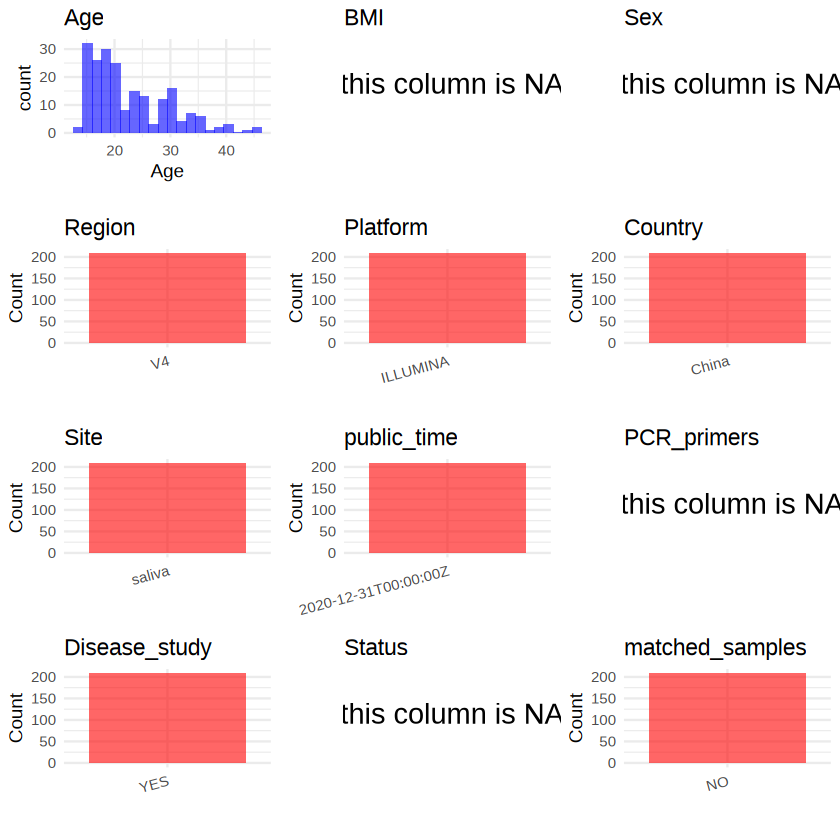

In [4]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [5]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJNA647054/metadata.csv", quote = F)